# Task 1 — Xử lý dữ liệu ảnh và biểu diễn ảnh (DeepFashion In-shop)

**Bài toán:** tìm đúng sản phẩm (*item_id*) trong kho ảnh shop từ một ảnh query — image-to-image retrieval.
Notebook này làm phần **Task 1 (30 điểm)** và chuẩn bị cấu hình cho Task 2:

| Yêu cầu đề bài | Ô |
|---|---|
| Hiểu dataset: đặc điểm, định dạng nhãn, phân bố, vấn đề chất lượng | 2–4 |
| Chiến lược train / validation / test, chống leakage | 5 |
| Pipeline: load → crop → pad → resize → normalize → batch | 6–7 |
| Augmentation (chỉ dùng khi train) | 8 |
| Biểu diễn ảnh: handcrafted (HSV histogram) và deep (CLIP) | 9 |
| Baseline + các cấu hình thay thế cho Task 2 | 10 |

**Cách chạy:** kernel `.venv/Scripts/python.exe` của dự án, chạy từ trên xuống.
Mọi ảnh minh hoạ lấy từ **split train**; official query/gallery chỉ được đếm thống kê, không dùng để chọn cấu hình.
Ô 9 nạp CLIP ViT-B/32 (đã có ở `.cache/clip/`) và encode vài chục ảnh — chạy được trên CPU, nhanh hơn trên GPU.


In [1]:
# 2. Đọc partition chính thức và bbox
%matplotlib inline
from pathlib import Path
from collections import Counter
import sys
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

ROOT = Path.cwd().resolve()
if not (ROOT / "vps").is_dir():
    ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT / "visual-product-search-pilot"
DATA = ROOT.parent  # thư mục môn học chứa img/, Eval/, list_bbox_inshop.txt
sys.path.insert(0, str(ROOT))
from vps.annotations import parse_partition, split_summary, validate_splits
from vps.preprocess import (CLOTHES_TYPES, CONFIGS, POSE_TYPES, BBoxCropPad, crop_box, hsv_histogram,
                            make_transform, pad_to_square, validation_split)
from vps.preprocess import parse_bbox

records = parse_partition((DATA / "Eval/list_eval_partition.txt").read_text())
boxes = parse_bbox((DATA / "list_bbox_inshop.txt").read_text())
assert set(boxes) == {r.path for r in records}, "bbox và partition phải cùng tập ảnh"
SPLITS = ("train", "query", "gallery")
by_split = {s: [r for r in records if r.split == s] for s in SPLITS}

print(f"{len(records):,} ảnh, {len({r.item_id for r in records}):,} sản phẩm, {len({r.category for r in records})} category")
for s, v in split_summary(records).items():
    print(f"  {s:8s}: {v['images']:6,} ảnh | {v['unique_items']:5,} item_id")
with Image.open(DATA / records[0].path) as im:
    print("Ví dụ:", records[0].path, im.size, im.mode, "| bbox:", boxes[records[0].path])


52,712 ảnh, 7,982 sản phẩm, 23 category
  train   : 25,882 ảnh | 3,997 item_id
  query   : 14,218 ảnh | 3,985 item_id
  gallery : 12,612 ảnh | 3,985 item_id
Ví dụ: img/WOMEN/Dresses/id_00000002/02_1_front.jpg (256, 256) RGB | bbox: BBox(clothes_type='3', pose_type='1', x1=65, y1=45, x2=233, y2=252)


### 3. Định dạng nhãn và phân bố

- `list_eval_partition.txt`: `image_name item_id evaluation_status` — split là `train`, `query` hoặc `gallery`.
- `list_bbox_inshop.txt`: `image_name clothes_type pose_type x_1 y_1 x_2 y_2` trên ảnh 256×256.
  `clothes_type`: 1 thân trên, 2 thân dưới, 3 toàn thân. `pose_type`: 1 trước, 2 nghiêng, 3 sau, 4 zoom-out, 5 zoom-in, 6 chỉ sản phẩm.
- Đây là bài toán **retrieval**, không phải phân loại: nhãn là *item_id*, category chỉ dùng để phân tích.


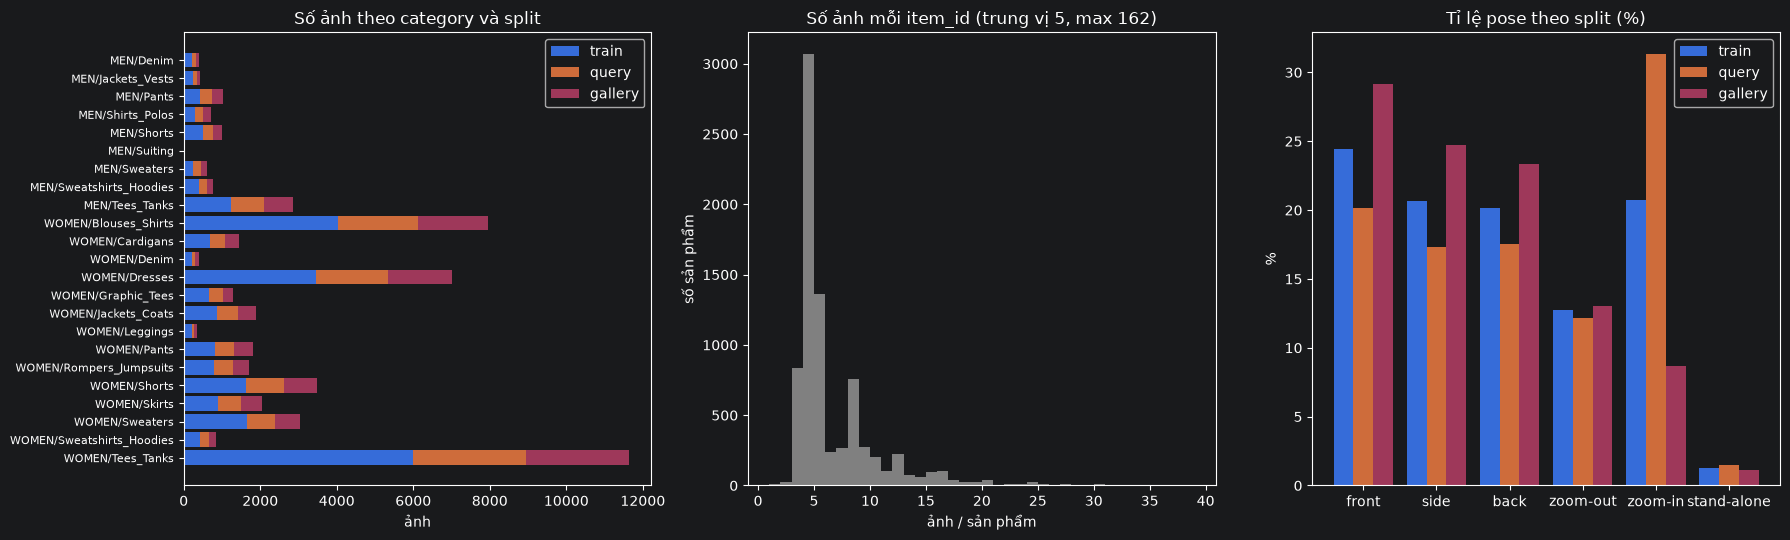

Tỉ lệ zoom-in: {'train': '20.7%', 'query': '31.3%', 'gallery': '8.6%'}
Mất cân bằng category: lớn nhất/nhỏ nhất = 11642 / 39


In [2]:
# 3. Phân bố category, số ảnh mỗi sản phẩm, pose theo split
cats = sorted({r.category for r in records})
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
bottom = np.zeros(len(cats))
for s in SPLITS:
    n = Counter(r.category for r in by_split[s])
    vals = np.array([n[c] for c in cats])
    axes[0].barh(cats, vals, left=bottom, label=s)
    bottom += vals
axes[0].set(title="Số ảnh theo category và split", xlabel="ảnh")
axes[0].legend(); axes[0].tick_params(axis="y", labelsize=8); axes[0].invert_yaxis()

per_id = np.array(list(Counter(r.item_id for r in records).values()))
axes[1].hist(per_id, bins=np.arange(1, 40), color="gray")
axes[1].set(title=f"Số ảnh mỗi item_id (trung vị {np.median(per_id):.0f}, max {per_id.max()})",
            xlabel="ảnh / sản phẩm", ylabel="số sản phẩm")

poses = list(POSE_TYPES)
x = np.arange(len(poses))
for k, s in enumerate(SPLITS):
    n = Counter(boxes[r.path].pose_type for r in by_split[s])
    axes[2].bar(x + (k - 1) * 0.27, [100 * n[p] / len(by_split[s]) for p in poses], 0.27, label=s)
axes[2].set_xticks(x, [POSE_TYPES[p] for p in poses])
axes[2].set(title="Tỉ lệ pose theo split (%)", ylabel="%"); axes[2].legend()
fig.tight_layout(); plt.show()

zoom = {s: sum(boxes[r.path].pose_type == "5" for r in by_split[s]) / len(by_split[s]) for s in SPLITS}
print("Tỉ lệ zoom-in:", {s: f"{v:.1%}" for s, v in zoom.items()})
print("Mất cân bằng category: lớn nhất/nhỏ nhất =",
      max(Counter(r.category for r in records).values()), "/", min(Counter(r.category for r in records).values()))


**Nhận xét cần đưa vào báo cáo:** category rất mất cân bằng; mỗi sản phẩm chỉ có vài ảnh (bài toán few-shot theo item).
Query có tỉ lệ ảnh **zoom-in** cao hơn hẳn gallery — query thường cận cảnh, gallery thường toàn thân —
đây là một lý do để thử crop theo bbox, giúp hai phía cùng tập trung vào sản phẩm.


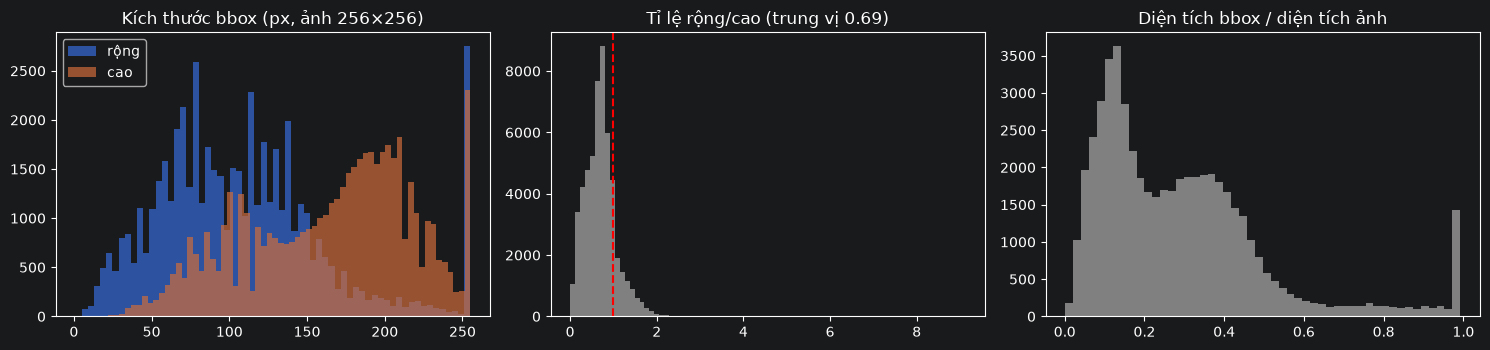

Bbox rộng < 32 px: 2,884 (5.5%); hẹp nhất 1 px. Cao < 32 px: 40
Pose của box hẹp: {'side': 2368, 'zoom-in': 367, 'front': 105, 'zoom-out': 38, 'back': 6}


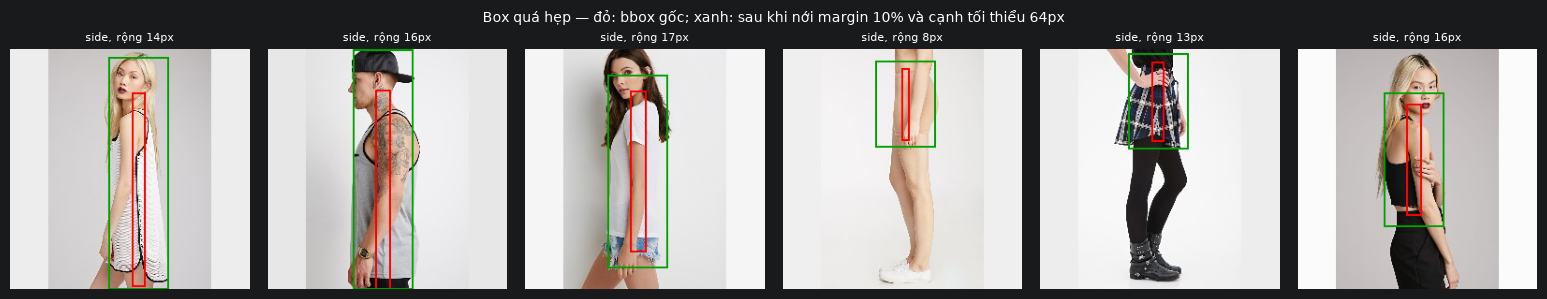

In [3]:
# 4. Chất lượng bbox: kích thước, tỉ lệ khung, box quá hẹp
b = np.array([[v.x1, v.y1, v.x2, v.y2] for v in boxes.values()])
w, h = b[:, 2] - b[:, 0], b[:, 3] - b[:, 1]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].hist(w, bins=64, alpha=0.7, label="rộng"); axes[0].hist(h, bins=64, alpha=0.7, label="cao")
axes[0].set(title="Kích thước bbox (px, ảnh 256×256)"); axes[0].legend()
axes[1].hist(w / h, bins=80, color="gray"); axes[1].axvline(1, color="red", ls="--")
axes[1].set(title=f"Tỉ lệ rộng/cao (trung vị {np.median(w / h):.2f})")
axes[2].hist(w * h / 256 ** 2, bins=50, color="gray")
axes[2].set(title="Diện tích bbox / diện tích ảnh")
fig.tight_layout(); plt.show()
narrow = w < 32
print(f"Bbox rộng < 32 px: {narrow.sum():,} ({narrow.mean():.1%}); hẹp nhất {w.min()} px. Cao < 32 px: {(h < 32).sum()}")
print("Pose của box hẹp:", {POSE_TYPES[k]: v for k, v in Counter(v.pose_type for v, n in zip(boxes.values(), narrow) if n).most_common()})

# Ảnh minh hoạ chọn cố định từ train (hash đường dẫn) để chạy lại ra cùng kết quả
import hashlib
def pick(pred, n):
    rs = [r for r in by_split["train"] if pred(r)]
    return sorted(rs, key=lambda r: hashlib.sha256(r.path.encode()).hexdigest())[:n]

def show_boxes(rs, title):
    fig, axes = plt.subplots(1, len(rs), figsize=(2.6 * len(rs), 3))
    for ax, r in zip(axes, rs):
        bb = boxes[r.path]
        with Image.open(DATA / r.path) as im:
            im = im.convert("RGB"); d = ImageDraw.Draw(im)
            d.rectangle([bb.x1, bb.y1, bb.x2, bb.y2], outline=(255, 0, 0), width=2)
            d.rectangle(crop_box(bb, *im.size), outline=(0, 160, 0), width=2)
        ax.imshow(im); ax.axis("off")
        ax.set_title(f"{POSE_TYPES[bb.pose_type]}, rộng {bb.width}px", fontsize=8)
    fig.suptitle(title, fontsize=10); fig.tight_layout(); plt.show()

show_boxes(pick(lambda r: boxes[r.path].width < 20, 6),
           "Box quá hẹp — đỏ: bbox gốc; xanh: sau khi nới margin 10% và cạnh tối thiểu 64px")


**Vấn đề chất lượng dữ liệu quan sát được:**

- Phần lớn box hẹp nằm ở ảnh **chụp nghiêng**: box chỉ khoanh một dải mảnh dọc mép trang phục, không bao trọn sản phẩm — nhiễu nhãn, không phải lỗi đọc file.
  Pipeline xử lý bằng margin + cạnh tối thiểu 64 px; phương án khác (dùng toàn ảnh khi box hẹp hơn ngưỡng) là tham số để chọn trên **val**.
- Ảnh đều 256×256 JPEG, không thiếu/hỏng (audit của pilot đã giải mã toàn bộ 52.712 ảnh).
- Một `item_id` có thể gồm nhiều màu của cùng mẫu, nên nhãn không tương đương một SKU màu duy nhất.
- Ảnh studio nền sáng, người mẫu chiếm phần lớn ảnh: model có thể dựa vào người mẫu/tư thế thay vì sản phẩm.


In [4]:
# 5. Chiến lược split và kiểm tra leakage
facts = validate_splits(records)          # raise nếu query/gallery trùng ảnh hoặc train/test trùng ID
val = validation_split(records)           # tách 10% item_id của train làm validation
for k, v in facts.items():
    if not k.endswith("examples"):
        print(f"  {k}: {v}")
ids = {k: {r.item_id for r in v} for k, v in val.items()}
test_ids = {r.item_id for r in by_split["query"] + by_split["gallery"]}
assert not ids["train"] & ids["val_query"], "train và val không chung sản phẩm"
assert not (ids["train"] | ids["val_query"]) & test_ids, "không chạm vào item của official test"
assert ids["val_query"] == ids["val_gallery"], "mỗi item val có cả ảnh query và gallery"
assert not {r.path for r in val["val_query"]} & {r.path for r in val["val_gallery"]}
print()
for k, v in val.items():
    print(f"  {k:12s}: {len(v):6,} ảnh | {len({r.item_id for r in v}):5,} item_id")


  query_gallery_path_overlap: 0
  train_eval_identity_overlap: 0
  query_items_without_gallery_positive: 0
  gallery_items_without_query: 0

  train       : 23,266 ảnh | 3,597 item_id
  val_query   :  1,232 ảnh |   400 item_id
  val_gallery :  1,384 ảnh |   400 item_id


| Tập | Dùng để | Ghi chú |
|---|---|---|
| **train** (90% item_id của split train) | Học/adapt ở Task 2 | Augmentation chỉ áp dụng ở đây |
| **val_query / val_gallery** (10% item_id của train) | Chọn cấu hình, margin, epoch, early stopping | Chia theo *sản phẩm*, cùng kiểu query→gallery như test |
| **official query / gallery** | Đánh giá cuối, **một lần** cho mỗi cấu hình đã chốt | Giữ toàn bộ 12.612 ảnh gallery làm distractor |

Chống leakage: (1) chia theo *item_id*, không chia theo ảnh — ảnh cùng sản phẩm không lọt giữa train và val/test;
(2) official split đảm bảo train và test không chung sản phẩm, query và gallery không chung ảnh (đã assert ở trên);
(3) audit của pilot không thấy ảnh trùng byte/pixel giữa các split; pHash tìm thấy cặp gần giống nhưng không tự loại;
(4) không chọn tham số trên test. Giới hạn: không loại trừ được việc CLIP từng thấy ảnh DeepFashion khi pretrain.


E:\Hoc tap\Mon hoc\Năm 3 kì 1\FCVG101-Computer_vision\visual-product-search-pilot\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


CLIP preprocess: Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x0000020B1EF57920>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)


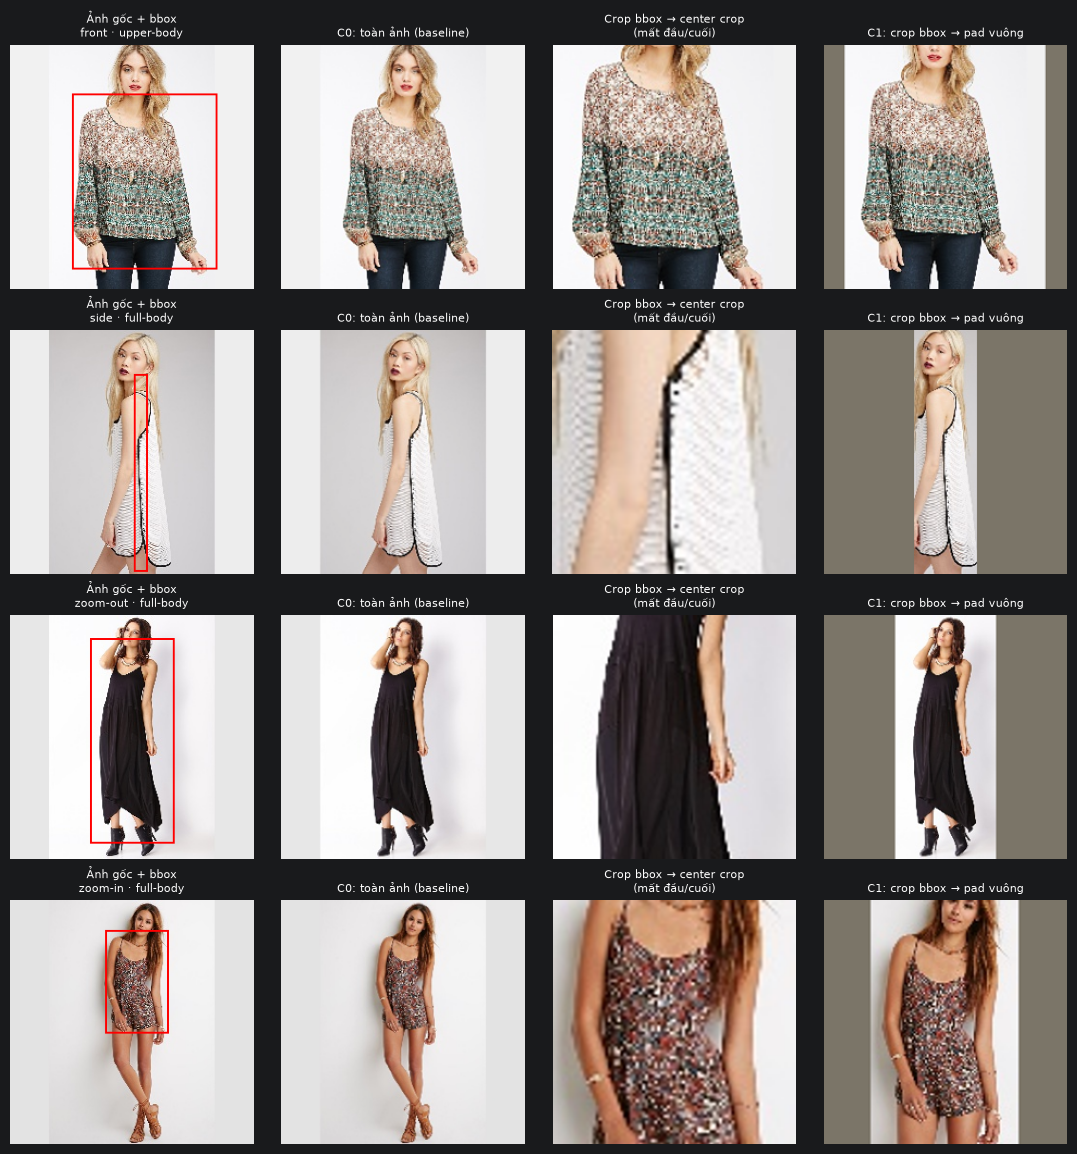

In [5]:
# 6. Pipeline từng bước trên ảnh train đại diện cho mỗi pose
import torch, clip
from torchvision import transforms as T
_, preprocess = clip.load(str(ROOT / ".cache/clip/ViT-B-32.pt"), device="cpu", jit=False)
print("CLIP preprocess:", preprocess)
MEAN = torch.tensor(preprocess.transforms[-1].mean).view(3, 1, 1)
STD = torch.tensor(preprocess.transforms[-1].std).view(3, 1, 1)
def visible(t):  # hoàn tác normalize CHỈ để hiển thị
    return (t * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

c0 = make_transform("C0_full", preprocess)
c1 = make_transform("C1_bbox_pad", preprocess, boxes)
def naive_crop(im, path):  # crop bbox rồi để CLIP center-crop luôn: phản ví dụ
    return preprocess(im.convert("RGB").crop(crop_box(boxes[path], *im.size)))

samples = [pick(lambda r, p=p: boxes[r.path].pose_type == p, 1)[0] for p in ("1", "2", "4", "5")]
cols = ["Ảnh gốc + bbox", "C0: toàn ảnh (baseline)", "Crop bbox → center crop\n(mất đầu/cuối)", "C1: crop bbox → pad vuông"]
fig, axes = plt.subplots(len(samples), 4, figsize=(11, 2.9 * len(samples)))
for row, r in zip(axes, samples):
    bb = boxes[r.path]
    with Image.open(DATA / r.path) as im:
        im = im.convert("RGB")
        shown = im.copy(); ImageDraw.Draw(shown).rectangle([bb.x1, bb.y1, bb.x2, bb.y2], outline=(255, 0, 0), width=2)
        views = [np.asarray(shown), visible(c0(im, r.path)), visible(naive_crop(im, r.path)), visible(c1(im, r.path))]
    for ax, v, title in zip(row, views, cols):
        ax.imshow(v); ax.axis("off"); ax.set_title(title, fontsize=8)
    row[0].set_title(f"{cols[0]}\n{POSE_TYPES[bb.pose_type]} · {CLOTHES_TYPES[bb.clothes_type]}", fontsize=8)
fig.tight_layout(); plt.show()


**Các bước pipeline và lý do:**

1. **Load + convert RGB** (PIL): đảm bảo 3 kênh dù file có mode khác.
2. **Crop theo bbox** (C1, C2): nới **10% mỗi cạnh** để giữ viền/cổ áo, nới cạnh tối thiểu **64 px** cho box nghiêng quá hẹp, rồi dịch box vào trong ảnh nếu tràn biên.
3. **Pad về hình vuông** bằng màu trung bình của CLIP: bbox thường cao hơn rộng, nếu đưa thẳng vào `Resize(224) + CenterCrop(224)` của CLIP sẽ cắt mất phần trên/dưới (cột 3).
   Màu pad bằng mean nên sau normalize gần bằng 0; nhưng nó khác nền trắng của studio, nên màu pad (mean / trắng) là tham số so trên val.
   **Kết quả val** (`reports/val_crop_ablation.json`): pad trắng 65,8% R@1 so với pad mean 53,6%; ảnh đầy đủ (C0) vẫn cao nhất 71,1% → Task 2 giữ C0.
4. **Resize 224 bicubic + center crop 224**: giữ đúng preprocessing CLIP đã học khi pretrain; với ảnh đã vuông bước crop không bỏ mất gì.
5. **ToTensor + Normalize** theo mean/std của CLIP.
6. **Batch** bằng `DataLoader` (ô 7). Embedding đầu ra được L2-normalize để cosine = tích vô hướng.


In [6]:
# 7. Batching: Dataset trả (tensor, item_id); DataLoader gom thành batch
class InShop(torch.utils.data.Dataset):
    def __init__(self, recs, transform):
        self.recs, self.transform = recs, transform
    def __len__(self):
        return len(self.recs)
    def __getitem__(self, i):
        r = self.recs[i]
        with Image.open(DATA / r.path) as im:
            return self.transform(im, r.path), r.item_id

loader = torch.utils.data.DataLoader(InShop(val["val_query"][:16], c1), batch_size=8, shuffle=False)
x, item_ids = next(iter(loader))
print("batch:", tuple(x.shape), x.dtype, "| item_id đầu:", item_ids[:3])
print(f"sau normalize: mean {x.mean():.3f}, std {x.std():.3f}, min {x.min():.2f}, max {x.max():.2f}")


batch: (8, 3, 224, 224) torch.float32 | item_id đầu: ('id_00000004', 'id_00000004', 'id_00000004')
sau normalize: mean 0.511, std 1.161, min -1.79, max 2.15


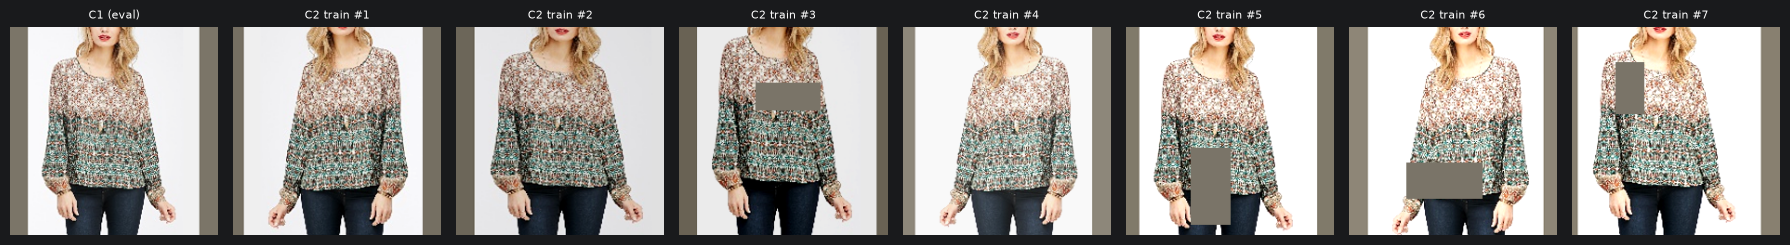

In [7]:
# 8. Augmentation cho train (C2) — eval vẫn dùng transform xác định của C1
c2_train = make_transform("C2_bbox_pad_aug", preprocess, boxes, train=True)
r = samples[0]
torch.manual_seed(0)
with Image.open(DATA / r.path) as im:
    im.load()
    views = [visible(c1(im, r.path))] + [visible(c2_train(im, r.path)) for _ in range(7)]
fig, axes = plt.subplots(1, 8, figsize=(18, 2.8))
for k, (ax, v) in enumerate(zip(axes, views)):
    ax.imshow(v); ax.axis("off"); ax.set_title("C1 (eval)" if k == 0 else f"C2 train #{k}", fontsize=8)
fig.tight_layout(); plt.show()


| Augmentation | Tham số | Lý do |
|---|---|---|
| RandomResizedCrop | scale 0.75–1, ratio 0.9–1.1 | Mô phỏng zoom/lệch khung giữa query và gallery |
| HorizontalFlip | p = 0.5 | Quần áo gần như đối xứng trái–phải |
| ColorJitter | **chỉ** brightness/contrast 0.2 | Ánh sáng studio thay đổi; **không** đổi hue/saturation vì màu là đặc trưng nhận diện sản phẩm |
| RandomErasing | p = 0.25, 2–10% diện tích | Mô phỏng che khuất bởi tay/tóc/phụ kiện |

Không dùng xoay lớn hay lật dọc: ảnh shop luôn thẳng đứng. Augmentation chỉ có tác dụng khi **train** (Task 2);
với model frozen ở baseline, C2 khi đánh giá bằng đúng C1.


5 query val × 1,384 ảnh val gallery; hạng của ảnh đúng sản phẩm đầu tiên (1 = tốt nhất):
  HSV (crop+pad)     dim= 128  hạng = [148, 8, 1, 1, 1]
  CLIP C0 toàn ảnh   dim= 512  hạng = [1, 1, 2, 1, 1]
  CLIP C1 crop+pad   dim= 512  hạng = [1, 1, 1, 1, 1]


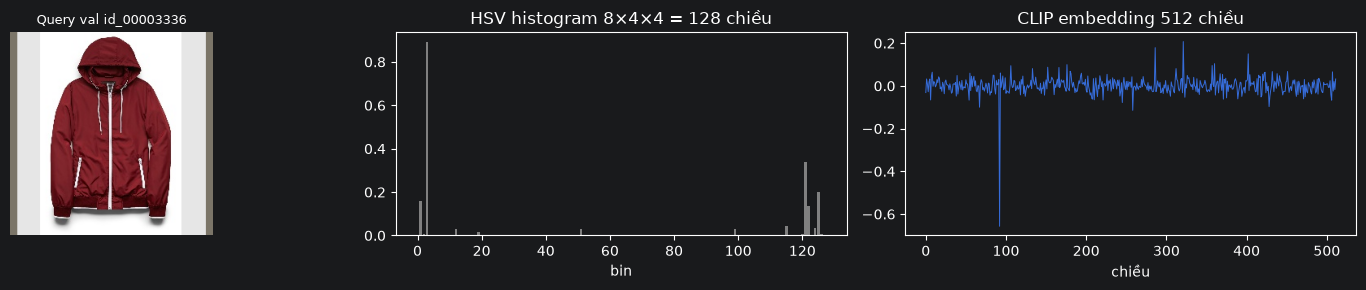

In [8]:
# 9. Biểu diễn ảnh: HSV histogram (handcrafted) so với CLIP embedding (deep), trên val
device = "cuda" if torch.cuda.is_available() else "cpu"
model, _ = clip.load(str(ROOT / ".cache/clip/ViT-B-32.pt"), device=device, jit=False)
model.eval()
crop = BBoxCropPad(boxes)

vq = sorted(val["val_query"], key=lambda r: hashlib.sha256(r.path.encode()).hexdigest())[:5]
vg = val["val_gallery"]
def load(r):
    with Image.open(DATA / r.path) as im:
        return im.convert("RGB")
@torch.inference_mode()
def clip_emb(recs, transform):
    x = torch.stack([transform(load(r), r.path) for r in recs]).to(device)
    f = model.encode_image(x).float()
    return (f / f.norm(dim=-1, keepdim=True)).cpu().numpy()

gal_ids = np.array([r.item_id for r in vg])
reps = {
    "HSV (crop+pad)": (np.stack([hsv_histogram(crop(load(r), r.path)) for r in vq]),
                       np.stack([hsv_histogram(crop(load(r), r.path)) for r in vg])),
    "CLIP C0 toàn ảnh": (clip_emb(vq, c0), clip_emb(vg, c0)),
    "CLIP C1 crop+pad": (clip_emb(vq, c1), clip_emb(vg, c1)),
}
print(f"{len(vq)} query val × {len(vg):,} ảnh val gallery; hạng của ảnh đúng sản phẩm đầu tiên (1 = tốt nhất):")
for name, (q, g) in reps.items():
    s = q @ g.T
    ranks = [int((s[i] > s[i][gal_ids == r.item_id].max()).sum()) + 1 for i, r in enumerate(vq)]
    print(f"  {name:18s} dim={q.shape[1]:4d}  hạng = {ranks}")

r = vq[0]
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
axes[0].imshow(crop(load(r), r.path)); axes[0].axis("off"); axes[0].set_title(f"Query val {r.item_id}", fontsize=9)
axes[1].bar(range(128), reps["HSV (crop+pad)"][0][0], color="gray")
axes[1].set(title="HSV histogram 8×4×4 = 128 chiều", xlabel="bin")
axes[2].plot(reps["CLIP C1 crop+pad"][0][0], linewidth=0.7)
axes[2].set(title="CLIP embedding 512 chiều", xlabel="chiều")
fig.tight_layout(); plt.show()


Ô 9 chỉ minh hoạ trên **5 query val** để thấy cách hai loại biểu diễn hoạt động — **không phải kết quả thực nghiệm**.
So sánh chính thức làm ở Task 2 trên toàn bộ val, chốt cấu hình, rồi mới chạy test một lần.

- **HSV histogram**: chỉ đếm màu, mất toàn bộ thông tin hình dạng/hoa văn; rẻ, dễ giải thích, là mốc dưới.
- **CLIP embedding**: đặc trưng ngữ nghĩa học từ 400 triệu cặp ảnh–văn bản; đã đo trên test: R@1 45,5% (C0).


In [9]:
# 10. Các cấu hình đưa sang Task 2
desc = {
    "C0_full": "Baseline: toàn ảnh, preprocessing CLIP gốc",
    "C1_bbox_pad": "Crop bbox (+10%, cạnh ≥ 64px) → pad vuông → CLIP",
    "C2_bbox_pad_aug": "C1 + augmentation khi train (crop/flip/sáng-tương phản/erasing)",
    "C3_hsv_hist": "Handcrafted: HSV histogram 128 chiều trên ảnh crop+pad",
}
print(f"{'Cấu hình':16s} {'crop':5s} {'aug':5s} {'biểu diễn':9s} mô tả")
for k, v in CONFIGS.items():
    print(f"{k:16s} {str(v['crop']):5s} {str(v['train_augment']):5s} {v['representation']:9s} {desc[k]}")


Cấu hình         crop  aug   biểu diễn mô tả
C0_full          False False clip      Baseline: toàn ảnh, preprocessing CLIP gốc
C1_bbox_pad      True  False clip      Crop bbox (+10%, cạnh ≥ 64px) → pad vuông → CLIP
C2_bbox_pad_aug  True  True  clip      C1 + augmentation khi train (crop/flip/sáng-tương phản/erasing)
C3_hsv_hist      True  False hsv       Handcrafted: HSV histogram 128 chiều trên ảnh crop+pad


**Thứ tự so sánh ở Task 2** (đổi một yếu tố mỗi lần, cùng split và cùng Recall@1/5):

1. C0 → C1 với CLIP frozen: tác động của **crop/pad** (chỉ đổi preprocessing).
2. C0 / C1 → C3: **deep vs handcrafted** cùng crop.
3. C1 → C2 khi **adapt** CLIP (ví dụ projection head hoặc fine-tune vài block cuối, train trên `train`, chọn epoch trên val): tác động của **augmentation**.

Chọn tham số (margin, cạnh tối thiểu, số epoch, learning rate) bằng **val**; official test chỉ chạy một lần cho mỗi cấu hình đã chốt.
